# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [59]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold


### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [2]:
def mean_absolute_error(y_true,y_pred):
    return np.mean(np.abs(np.array(y_true)-np.array(y_pred)))

#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [3]:
def mean_sqaered_error(y_true,y_pred):
    return np.mean((np.array(y_true)-np.array(y_pred))**2)

#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [4]:
def rootMSE(y_true, y_pred):
    return np.sqrt(mean_sqaered_error(y_true, y_pred))

#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [5]:
def MAPE (y_true, y_pred):
    y_true= np.array(y_true)
    y_pred= np.array(y_pred)

    return np.mean(np.abs((y_true- y_pred)/y_true))*100

#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [55]:
def R2_score(y_true, y_pred):
    y_true=np.array(y_true)
    y_pred=np.array(y_pred)

    sse=np.sum((y_true-y_pred)**2)
    sst=np.sum((y_true-np.mean(y_true))**2)

    return (sst-sse)/sst

### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [32]:
adv_data= pd.read_csv("advertising.csv")
x= adv_data.drop("Sales",axis=1)
x=x.drop(columns=x.columns[0])
y=adv_data["Sales"]

In [33]:
print("featuresshape", x.shape)
print("target", y.shape)

print(x.head())
print(y.head())


featuresshape (200, 3)
target (200,)
      TV  Radio  Newspaper
0  230.1   37.8       69.2
1   44.5   39.3       45.1
2   17.2   45.9       69.3
3  151.5   41.3       58.5
4  180.8   10.8       58.4
0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: Sales, dtype: float64


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.782224
Radio      0.054809  1.000000   0.354104  0.576223
Newspaper  0.056648  0.354104   1.000000  0.228299
Sales      0.782224  0.576223   0.228299  1.000000


<Axes: >

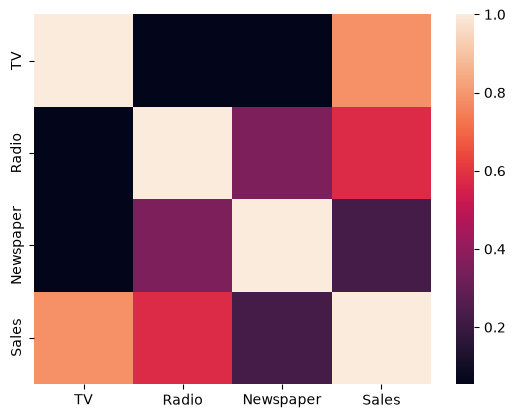

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
corr=adv_data.drop(columns=adv_data.columns[0]).corr()
print(corr)
sns.heatmap(corr)

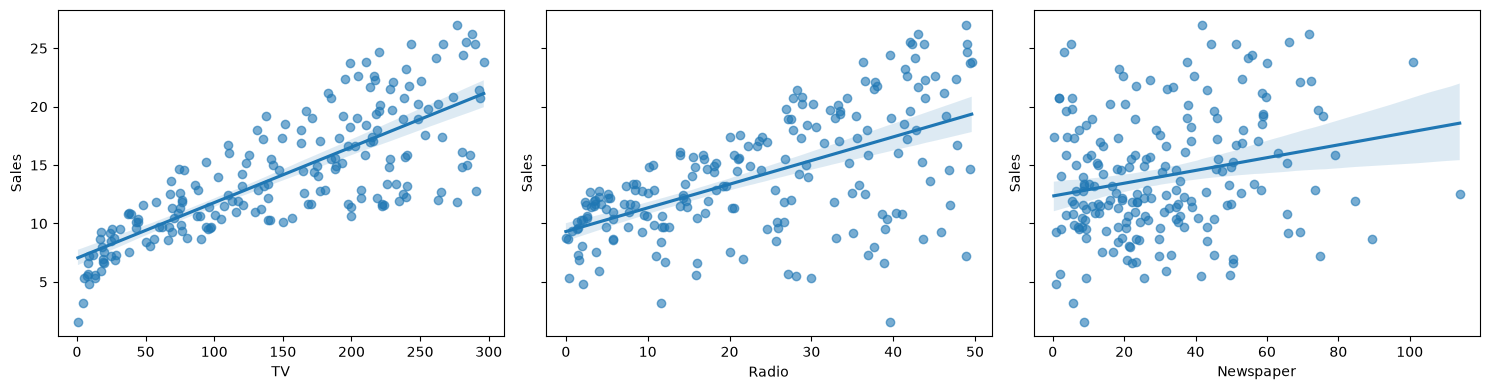

In [167]:
fig,axes=plt.subplots(1,3,figsize=(15,4),sharey=True)
for ax,col in zip(axes,['TV',"Radio","Newspaper"]):
    sns.regplot(x=col,y="Sales",data=adv_data,ax=ax, scatter_kws={"alpha":0.6})
plt.tight_layout()
plt.show()

The corralation between sales and tv advertising is the strongest.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [103]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.33, random_state=17)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

scaler = StandardScaler()

X_train= scaler.fit_transform(X_train)
X_test= scaler.transform(X_test)

(134, 3) (134,) (66, 3) (66,)


#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [101]:
model = LinearRegression(fit_intercept=True)

model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 3.97, 2.88,-0.07]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,14.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[13.67,11.09, 9.6 ]"


In [102]:
print(model.intercept_) # b0
print(model.coef_)
# Generate predictions
y_pred = model.predict(X_test)

14.022388059701495
[ 3.9675339   2.88155345 -0.07344038]


#### 2.5 Evaluate created model with above functions

In [99]:
print("MAE score:", mean_absolute_error(y_test, y_pred))
print("MSE score:", mean_sqaered_error(y_test, y_pred))
print("RMSE score:", rootMSE(y_test, y_pred))
print("R^2 score:", R2_score(y_test, y_pred))


MAE score: 1.517343735777843
MSE score: 4.911579294712751
RMSE score: 2.216208314827997
R^2 score: 0.7900185956121483


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [65]:
from sklearn.model_selection import cross_val_score
k = 10 
kf = KFold(n_splits=k, shuffle=True, random_state=42)

scores= cross_val_score(model,X_train,y_train,cv=kf,scoring="r2")
print('R2 scores: ',scores)
print("mean r2 score: ", scores.mean())

R2 scores:  [0.85325246 0.84823738 0.96513975 0.87639732 0.88554603 0.88664682
 0.9412525  0.83058494 0.92888987 0.84439962]
mean r2 score:  0.8860346690377213


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [94]:
X_new =x.drop(columns=['TV'])


X_train_new, X_test_new, y_train, y_test = train_test_split(
    x, y, test_size=0.33, random_state=17)


scaler_new = StandardScaler()

X_train_new= scaler_new.fit_transform(X_train_new)
X_test_new= scaler_new.transform(X_test_new)

model_new=LinearRegression()
model.fit(X_train_new, y_train)





,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 3.97, 2.88,-0.07]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,14.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[13.67,11.09, 9.6 ]"


In [95]:
scores= cross_val_score(model,X_train_new,y_train,cv=kf,scoring="r2")
print('R2 scores: ',scores)
print("mean r2 score: ", scores.mean())


R2 scores:  [0.78545128 0.85841694 0.92369778 0.92462028 0.86632943 0.95745304
 0.89027228 0.88491403 0.93054362 0.83829662]
mean r2 score:  0.8859995306404489


There was no significant difference between the models perfomance.

### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [104]:
from sklearn.linear_model import Lasso
lasso = Lasso(alpha=1)
lasso.fit(X_train, y_train)

y_pred = lasso.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse}")
print("Coefficients:", lasso.coef_)

Mean Squared Error: 4.911579294712751
Coefficients: [3.0619592  1.96202634 0.        ]


#### 3.2 Ridge regression

In [107]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
y_pred = ridge.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)
print("Coefficients:", ridge.coef_)

Mean Squared Error: 3.4768894774722394
Coefficients: [ 3.93899368  2.85996406 -0.06218255]


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [109]:
from sklearn.linear_model import ElasticNet


elastic_net = ElasticNet(alpha=1.0, l1_ratio=0.5)
elastic_net.fit(X_train, y_train)

y_pred = elastic_net.predict(X_test)
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)
print("Coefficients:", elastic_net.coef_)

Mean Squared Error: 6.8438833201041085
Coefficients: [2.39397459 1.68907463 0.01489489]


#### 3.4 Make conclusions

The largest MSE is from elastic net regression, meaning it has the biggest difference between predictions and true values. However ridge regression has the smallest MSE.

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [144]:
def Accuracy (TRUE_PRED,TOTAL_PRED):
    accuracy=np.sum(TRUE_PRED==TOTAL_PRED)/len(TRUE_PRED)
    return accuracy


#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [149]:
def precsion(TRUE_PRED,TOTAL_PRED):
    TRUE_PRED,TOTAL_PRED=np.asarray(TRUE_PRED), np.asarray(TOTAL_PRED)
    predicted_pos=TOTAL_PRED ==1
    return(TRUE_PRED[predicted_pos] == 1).mean()


#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [154]:
def Recall(TRUE_PRED,TOTAL_PRED):
    TRUE_PRED,TOTAL_PRED=np.asarray(TRUE_PRED), np.asarray(TOTAL_PRED)
    predicted_pos=TRUE_PRED ==1
    return(TOTAL_PRED[predicted_pos] == 1).mean()

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [158]:
def F1(TRUE_PRED, TOTAL_PRED):
    P=precsion(TRUE_PRED, TOTAL_PRED)
    R=Recall(TRUE_PRED, TOTAL_PRED)
    return 2*P*R/(P+R)

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [117]:
diabetes_data= pd.read_csv("diabetes.csv")
colummns=["Glucose", "BloodPressure","SkinThickness","Insulin","BMI"]
for col in colummns:
    diabetes_data[col]=diabetes_data[col].replace(0,diabetes_data[col].mean())


h = diabetes_data.drop("Outcome",axis=1)
m = diabetes_data["Outcome"]


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

                          Pregnancies   Glucose  BloodPressure  SkinThickness  \
Pregnancies                  1.000000  0.127964       0.208984       0.013376   
Glucose                      0.127964  1.000000       0.219666       0.160766   
BloodPressure                0.208984  0.219666       1.000000       0.134155   
SkinThickness                0.013376  0.160766       0.134155       1.000000   
Insulin                     -0.018082  0.396597       0.010926       0.240361   
BMI                          0.021546  0.231478       0.281231       0.535703   
DiabetesPedigreeFunction    -0.033523  0.137106       0.000371       0.154961   
Age                          0.544341  0.266600       0.326740       0.026423   
Outcome                      0.221898  0.492908       0.162986       0.175026   

                           Insulin       BMI  DiabetesPedigreeFunction  \
Pregnancies              -0.018082  0.021546                 -0.033523   
Glucose                   0.396597  0.231

<Axes: >

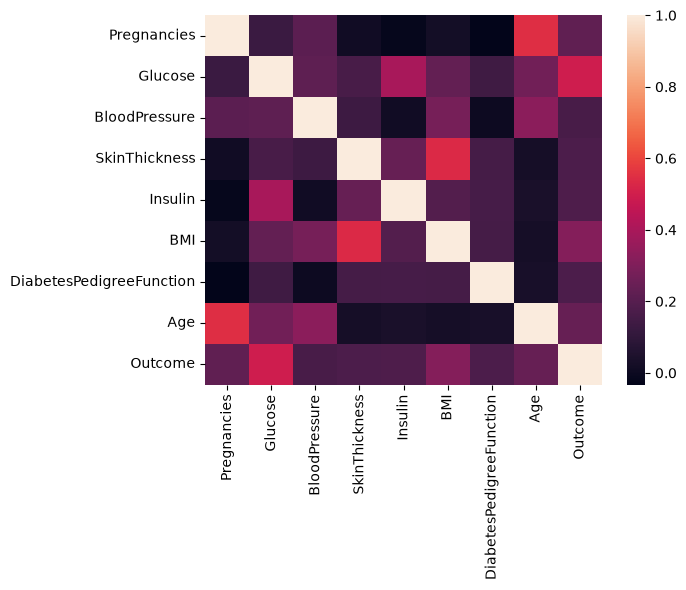

In [120]:
corr2=diabetes_data.corr()
print(corr2)
sns.heatmap(corr2)

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [121]:
h_train, h_test, m_train, m_test = train_test_split(
    h, m, test_size=0.33, random_state=17)
print(h_train.shape, m_train.shape, h_test.shape, m_test.shape)

scaler = StandardScaler()

h_train= scaler.fit_transform(h_train)
h_test= scaler.transform(h_test)

(514, 8) (514,) (254, 8) (254,)


#### 2.4 Fit logistic regression model, generate predictions

In [124]:
logreg = LogisticRegression()
logreg.fit(h_train, m_train)

m_pred_log = logreg.predict(h_test)
m_pred_log[:10]

array([0, 1, 0, 0, 0, 0, 0, 1, 1, 1])

#### 2.5 Create a confusion matrix and evaluate created model with above functions

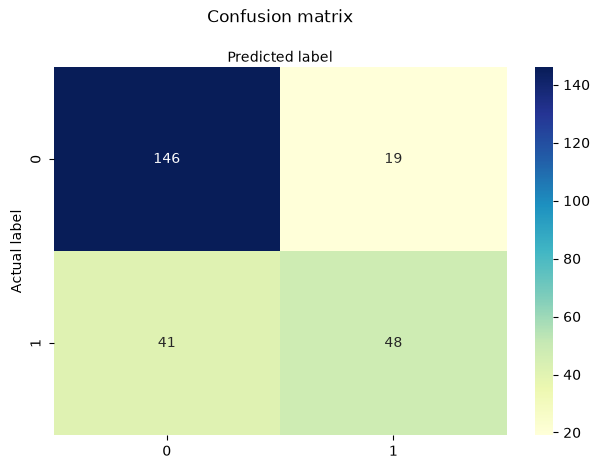

0.7637795275590551
0.7164179104477612
0.5393258426966292
0.6153846153846154


In [159]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cnf_matrix = confusion_matrix(m_test, m_pred_log)
cnf_matrix

class_names = [0, 1] # names of classes
fig, ax = plt.subplots()
# Create heatmap (seaborn places the tick labels in the centre of each cell)
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu", fmt='g',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.xaxis.set_label_position("top")
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()


print(Accuracy(m_test,m_pred_log))

print(precsion(m_test,m_pred_log))

print(Recall(m_test,m_pred_log))

print(F1(m_test,m_pred_log))



#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

AUC: 0.8332311882873681


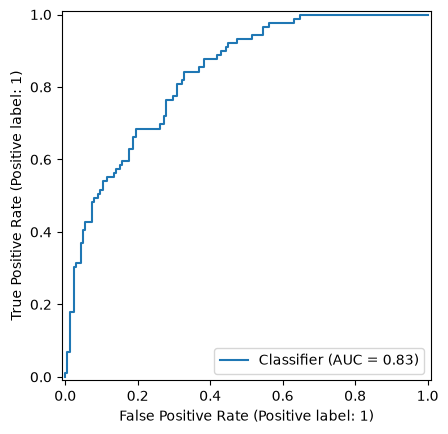

In [133]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay

m_proba= logreg.predict_proba(h_test)[:,1]

auc= roc_auc_score(m_test,m_proba)
print('AUC:',auc)

RocCurveDisplay.from_predictions(m_test,m_proba)
plt.show()


#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [136]:


means= cross_val_score(logreg,h_train,m_train,cv=10,scoring="accuracy")
print('acc scores: ',means)
print("mean acc score: ", means.mean())

acc scores:  [0.67307692 0.82692308 0.78846154 0.75       0.70588235 0.76470588
 0.88235294 0.74509804 0.74509804 0.80392157]
mean acc score:  0.768552036199095


### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [139]:
from sklearn.tree import DecisionTreeClassifier


clf = DecisionTreeClassifier(random_state=42)
clf.fit(h_train, m_train)

m_pred_clf = clf.predict(h_test)
m_pred_clf[:10]

array([0, 1, 0, 0, 0, 1, 0, 1, 1, 1])

#### 3.2 Evaluate created model with above functions

In [168]:


print(Accuracy(m_test,m_pred_clf))

print(precsion(m_test,m_pred_clf))

print(Recall(m_test,m_pred_clf))

print(F1(m_test,m_pred_clf))

0.7716535433070866
0.6741573033707865
0.6741573033707865
0.6741573033707865


#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

AUC: 0.7491998638066053


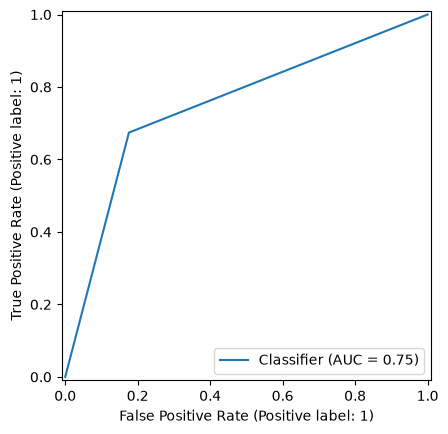

In [140]:
proba= clf.predict_proba(h_test)[:,1]

auc= roc_auc_score(m_test,proba)
print('AUC:',auc)

RocCurveDisplay.from_predictions(m_test,proba)
plt.show()

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [141]:
means2= cross_val_score(clf,h_train,m_train,cv=10,scoring="accuracy")
print('acc scores: ',means2)
print("mean acc score: ", means2.mean())

acc scores:  [0.61538462 0.73076923 0.73076923 0.75       0.56862745 0.70588235
 0.84313725 0.66666667 0.68627451 0.82352941]
mean acc score:  0.7121040723981901


#### 3.5 Make conclusions

The decision tree reached a mean accuracy of about 0.71, so it classifies roughly 7 of 10 correctly. The ROC curve has a bend at fpr=0.2 and tpr=6.7.The AUC of 0.75 is moderate and there is room for improvment.
Logistic regression reached AUC of 0.83 which beat out decision tree. Logistic regression varied less between folds (std=0.06 vs 0.085), so it seems more stable.